# MERGE DL Baseline: Wav2Vec2 + RoBERTa (Audio, Lirik, Bimodal)

Notebook ini menggantikan pipeline attention lama dengan **baseline deep learning paper MERGE** (arXiv 2407.06060) untuk klasifikasi quadrant emosi.

Konfigurasi utama:

- **Audio-only**: Wav2Vec2-large, hidden states 25 layer x 1024 dimensi, rata-rata timestep, Conv1D + Flatten -> embedding 1024, dua dense layer.
- **Lirik-only**: RoBERTa-large, seluruh lirik (dipotong 512 karakter), word embedding -> dua dense layer.
- **Bimodal**: early fusion concatenation audio 1024 + lirik 1024 = 2048, dense 2048 -> 100 -> 4.
- **Split**: 70-15-15 dan 40-30-30, masing-masing dataset/model.
- **Tuning**: Optuna Bayesian (TPE), optimizer SGD/Adam/Adamax, LR 1e-5..1e-2, batch size audio 32..256, bimodal 16..128, early stopping 15 epoch.
- **Metrik**: accuracy, precision, recall, F1 (macro dan weighted), per-class report, dan confusion matrix. F1 macro menjadi metrik utama sesuai paper.

> Notebook lama tetap tersimpan di `merge_attention_mtl_backup.ipynb`.


## 0. Prasyarat

Environment membutuhkan `torch`, `transformers`, `optuna`, `librosa`, `soundfile`, `scikit-learn`, `pandas`, `numpy`, dan `matplotlib`.

Jika belum tersedia, jalankan sekali di environment notebook:

```python
# %pip install -q "transformers>=4.40" optuna librosa soundfile
```

Model default yang diunduh:

- `facebook/wav2vec2-large-960h` (25 hidden states, 1024 dimensi)
- `sentence-transformers/all-roberta-large-v1` (1024 dimensi; sesuai paper MERGE)

Ekstraksi fitur jauh lebih cepat di GPU. Notebook tetap bisa berjalan di CPU, tetapi Wav2Vec2-large pada ribuan audio 30 detik akan sangat lambat. Semua hasil ekstraksi disimpan ke cache dan dapat dilanjutkan (`resume`).


In [1]:
# ============================================================
# 1. Import dan konfigurasi
# ============================================================
import contextlib
import json
import os
import random
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

try:
    import optuna
    from transformers import (
        AutoModel,
        AutoTokenizer,
        Wav2Vec2FeatureExtractor,
        Wav2Vec2Model,
    )
except Exception as exc:
    raise RuntimeError(
        "Dependensi belum lengkap. Jalankan: %pip install -q 'transformers>=4.40' "
        "optuna librosa soundfile"
    ) from exc

try:
    from IPython.display import display
except Exception:
    display = print


def find_project_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "data" / "audio").is_dir() and (cand / "data" / "lyrics").is_dir():
            return cand
        if (cand / "MERGE_Bimodal_Complete" / "data" / "audio").is_dir():
            return cand / "MERGE_Bimodal_Complete"
    return p


ROOT = find_project_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# ---------- Dataset ----------
# Semua dataset memakai sumber yang sama: data/audio dan data/lyrics.
DATA_ROOT = ROOT / "data"
SHARED_METADATA = "merge_bimodal_complete_metadata.csv"
SHARED_SPLIT_SUFFIX = "bimodal_complete"
DATASET_SPECS = {
    "Audio": dict(
        root=DATA_ROOT,
        metadata=SHARED_METADATA,
        split_suffix=SHARED_SPLIT_SUFFIX,
        audio_subdir="audio",
        lyric_subdir=None,
    ),
    "Lirik": dict(
        root=DATA_ROOT,
        metadata=SHARED_METADATA,
        split_suffix=SHARED_SPLIT_SUFFIX,
        audio_subdir=None,
        lyric_subdir="lyrics",
    ),
    "Bimodal": dict(
        root=DATA_ROOT,
        metadata=SHARED_METADATA,
        split_suffix=SHARED_SPLIT_SUFFIX,
        audio_subdir="audio",
        lyric_subdir="lyrics",
    ),
}

DATASET_ORDER = ["Audio", "Lirik", "Bimodal"]
SPLITS = ["tvt_70_15_15", "tvt_40_30_30"]
SPLIT_PARTS = [("train", "train"), ("validation", "validate"), ("test", "test")]
CLASS_ORDER = ["Q1", "Q2", "Q3", "Q4"]

# ---------- Model dan fitur ----------
WAV2VEC_MODEL = "facebook/wav2vec2-large-960h"
ROBERTA_MODEL = "sentence-transformers/all-roberta-large-v1"
AUDIO_SR = 16000
AUDIO_SECONDS = 30.0
MAX_CHARS = 512
AUDIO_DIM = 1024
AUDIO_LAYERS = 25
TEXT_DIM = 1024
DENSE1 = 2048
DENSE2 = 100
DROPOUT = 0.3
N_CLASSES = len(CLASS_ORDER)

# ---------- Training dan Optuna ----------
SEED = 42
N_TRIALS = 10
MAX_EPOCHS = 100
PATIENCE = 15
MIN_DELTA = 1e-4
BS_AUDIO = [32, 64, 128, 256]
BS_BIMODAL = [16, 32, 64, 128]
RESUME_RESULTS = True
EXTRACT_AUDIO = True
EXTRACT_LYRICS = True
FORCE_RECOMPUTE = False

# ---------- Path output ----------
FEATURE_DIR = ROOT / "features" / "paper_dl"
AUDIO_CACHE = FEATURE_DIR / "wav2vec2"
LYRIC_CACHE = FEATURE_DIR / "roberta"
RESULTS_DIR = ROOT / "results" / "paper_dl"
CKPT_DIR = ROOT / "checkpoints" / "paper_dl"
for folder in [FEATURE_DIR, AUDIO_CACHE, LYRIC_CACHE, RESULTS_DIR, CKPT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AUDIO_FEATURE_BATCH = 4 if DEVICE.type == "cuda" else 1
TEXT_FEATURE_BATCH = 16 if DEVICE.type == "cuda" else 4

optuna.logging.set_verbosity(optuna.logging.WARNING)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


print("Project root :", ROOT)
print("Device       :", DEVICE)
print("PyTorch      :", torch.__version__)
print("Optuna       :", optuna.__version__)
print("Wav2Vec2     :", WAV2VEC_MODEL)
print("RoBERTa      :", ROBERTA_MODEL)
if DEVICE.type != "cuda":
    print("\nPERINGATAN: CUDA tidak tersedia. Ekstraksi Wav2Vec2-large di CPU akan sangat lambat.")

Project root : D:\PELAJARAN\Semester 5\MACHINE LEARNING\Projek\MERGE_Bimodal_Complete
Device       : cuda
PyTorch      : 2.14.1+cu130
Optuna       : 5.1.0
Wav2Vec2     : facebook/wav2vec2-large-960h
RoBERTa      : sentence-transformers/all-roberta-large-v1


## 2. Muat metadata dan split

Semua model memakai sumber data yang sama: audio diambil dari `data/audio` dan lirik dari `data/lyrics`. Metadata `data/merge_bimodal_complete_metadata.csv` memetakan `Audio_Song` dan `Lyric_Song` ke `Quadrant`, sedangkan split TVT dibaca dari `data/tvt_dataframes/...`.

Audio-only memakai kolom `Audio_Song`, lirik-only memakai kolom `Lyric_Song`, dan bimodal memakai pasangan keduanya. Semua file yang dirujuk harus ada.

In [2]:
# ============================================================
# 2. Muat metadata dan split tiap dataset
# ============================================================
# Semua dataset memakai sumber yang sama: audio dari data/audio,
# lirik dari data/lyrics, dan split dari data/tvt_dataframes.
META_PATH = DATASET_SPECS["Bimodal"]["root"] / DATASET_SPECS["Bimodal"]["metadata"]
if not META_PATH.exists():
    raise FileNotFoundError(META_PATH)
META = pd.read_csv(META_PATH, dtype=str)
META.columns = [c.strip() for c in META.columns]
if not {"Audio_Song", "Lyric_Song", "Quadrant"}.issubset(META.columns):
    raise ValueError(f"Kolom metadata tidak lengkap: {list(META.columns)}")

META["audio_id"] = META["Audio_Song"].astype(str).str.strip()
META["lyric_id"] = META["Lyric_Song"].astype(str).str.strip()
META["label_name"] = META["Quadrant"].astype(str).str.strip()
LYRIC_TO_AUDIO = dict(zip(META["lyric_id"], META["audio_id"]))

unknown = sorted(set(META["label_name"]) - set(CLASS_ORDER))
if unknown:
    raise ValueError(f"Label quadrant tidak dikenal: {unknown}")

# Pemetaan Song audio -> split untuk tiap konfigurasi TVT.
SPLIT_MAPS = {}
for split in SPLITS:
    split_map = {}
    for part, fname in SPLIT_PARTS:
        p = (DATASET_SPECS["Bimodal"]["root"] / "tvt_dataframes" / split
             / f"{split}_{fname}_{SHARED_SPLIT_SUFFIX}.csv")
        if not p.exists():
            raise FileNotFoundError(p)
        sdf = pd.read_csv(p, dtype=str)
        sdf.columns = [c.strip() for c in sdf.columns]
        if "Song" not in sdf.columns:
            raise ValueError(f"Kolom Song tidak ada di {p}")
        for sid in sdf["Song"].astype(str).str.strip():
            if sid in split_map:
                raise ValueError(f"Song duplikat antar-part di {p}: {sid}")
            split_map[sid] = part
    SPLIT_MAPS[split] = split_map

DATA = {}
for name, spec in DATASET_SPECS.items():
    has_audio = spec["audio_subdir"] is not None
    has_lyric = spec["lyric_subdir"] is not None
    df = pd.DataFrame({
        "audio_id": META["audio_id"] if has_audio else None,
        "lyric_id": META["lyric_id"] if has_lyric else None,
        "label_name": META["label_name"],
    })
    df["label_idx"] = df["label_name"].map({c: i for i, c in enumerate(CLASS_ORDER)})

    # Verifikasi file audio/lirik.
    audio_missing, lyric_missing = [], []
    if has_audio:
        for q, aid in zip(df["label_name"], df["audio_id"]):
            p = spec["root"] / spec["audio_subdir"] / q / f"{aid}.mp3"
            if not p.exists():
                audio_missing.append(str(p))
    if has_lyric:
        for q, lid in zip(df["label_name"], df["lyric_id"]):
            p = spec["root"] / spec["lyric_subdir"] / q / f"{lid}.txt"
            if not p.exists():
                lyric_missing.append(str(p))
    if audio_missing or lyric_missing:
        raise FileNotFoundError(
            f"File hilang di {name}: audio={audio_missing[:3]}, lirik={lyric_missing[:3]}"
        )

    # Split selalu berasal dari Song audio; Song lirik dipetakan lewat metadata.
    split_source = df["audio_id"].where(
        df["audio_id"].notna(), df["lyric_id"].map(LYRIC_TO_AUDIO)
    )
    for split in SPLITS:
        part_df = df.copy()
        part_df["split"] = split_source.map(SPLIT_MAPS[split])
        missing = part_df[part_df["split"].isna()]
        if len(missing):
            raise ValueError(f"{len(missing)} lagu {name} tidak ada di split {split}")
        part_df = part_df.sort_values(["split", "label_idx"]).reset_index(drop=True)
        DATA[(name, split)] = part_df
        print(f"\n{name} | {split}: {len(part_df)} lagu")
        print(pd.crosstab(part_df["split"], part_df["label_name"]).reindex(
            ["train", "validation", "test"]
        ).to_string())


Audio | tvt_70_15_15: 2216 lagu
label_name   Q1   Q2   Q3   Q4
split                         
train       365  477  346  364
validation   80   98   77   77
test         80   98   77   77

Audio | tvt_40_30_30: 2216 lagu
label_name   Q1   Q2   Q3   Q4
split                         
train       207  275  194  212
validation  159  199  153  153
test        159  199  153  153

Lirik | tvt_70_15_15: 2216 lagu
label_name   Q1   Q2   Q3   Q4
split                         
train       365  477  346  364
validation   80   98   77   77
test         80   98   77   77

Lirik | tvt_40_30_30: 2216 lagu
label_name   Q1   Q2   Q3   Q4
split                         
train       207  275  194  212
validation  159  199  153  153
test        159  199  153  153

Bimodal | tvt_70_15_15: 2216 lagu
label_name   Q1   Q2   Q3   Q4
split                         
train       365  477  346  364
validation   80   98   77   77
test         80   98   77   77

Bimodal | tvt_40_30_30: 2216 lagu
label_name   Q1   Q2   

## 3. Ekstraksi fitur dan cache

### 3a. Audio Wav2Vec2

Untuk setiap file audio:

1. Muat MP3 pada 16 kHz, mono, maksimum 30 detik.
2. Jalankan Wav2Vec2-large tanpa head klasifikasi dengan `output_hidden_states=True`.
3. Ambil seluruh 25 hidden states, rata-rata sepanjang timestep (mask padding diabaikan).
4. Simpan matriks `(1024, 25)` ke `features/paper_dl/wav2vec2/`.

File cache yang sudah ada dan bentuknya sesuai akan dilewati. Hapus/ubah `FORCE_RECOMPUTE = True` bila ingin ekstraksi ulang.


In [4]:
# ============================================================
# 3a. Ekstraksi fitur audio Wav2Vec2
# ============================================================
def audio_path(spec, quadrant, audio_id):
    return spec["root"] / spec["audio_subdir"] / quadrant / f"{audio_id}.mp3"


def lyric_path(spec, quadrant, lyric_id):
    return spec["root"] / spec["lyric_subdir"] / quadrant / f"{lyric_id}.txt"


def cache_path(cache_dir, quadrant, item_id):
    return cache_dir / f"{quadrant}_{item_id}.npy"


def collect_feature_tasks():
    audio_tasks, lyric_tasks = {}, {}
    for (name, _split), df in DATA.items():
        spec = DATASET_SPECS[name]
        if spec["audio_subdir"] is not None:
            for q, aid in zip(df["label_name"], df["audio_id"]):
                audio_tasks[(q, aid)] = audio_path(spec, q, aid)
        if spec["lyric_subdir"] is not None:
            for q, lid in zip(df["label_name"], df["lyric_id"]):
                lyric_tasks[(q, lid)] = lyric_path(spec, q, lid)
    return audio_tasks, lyric_tasks


AUDIO_TASKS, LYRIC_TASKS = collect_feature_tasks()
print(f"Audio unik: {len(AUDIO_TASKS)} | Lirik unik: {len(LYRIC_TASKS)}")


def _amp_context():
    return torch.autocast("cuda", dtype=torch.float16) if DEVICE.type == "cuda" else contextlib.nullcontext()


def extract_audio_cache(force=False):
    import librosa  # import lokal agar sel data/model tetap bisa dipakai tanpa audio lib

    pending = []
    for (q, sid), src in AUDIO_TASKS.items():
        out = cache_path(AUDIO_CACHE, q, sid)
        if out.exists() and not force:
            try:
                arr = np.load(out)
                if arr.shape == (AUDIO_DIM, AUDIO_LAYERS):
                    continue
            except Exception:
                pass
        pending.append((q, sid, src, out))

    print(f"Audio cache tersedia: {len(AUDIO_TASKS) - len(pending)} / {len(AUDIO_TASKS)}")
    if not pending:
        print("Semua fitur audio sudah ada.")
        return

    feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(
        WAV2VEC_MODEL, return_attention_mask=True
    )
    model = Wav2Vec2Model.from_pretrained(WAV2VEC_MODEL).to(DEVICE).eval()
    failed, done = [], 0
    t0 = time.time()

    for start in range(0, len(pending), AUDIO_FEATURE_BATCH):
        chunk = pending[start:start + AUDIO_FEATURE_BATCH]
        waves = []
        for q, sid, src, out in chunk:
            try:
                wav, _ = librosa.load(
                    str(src), sr=AUDIO_SR, mono=True, duration=AUDIO_SECONDS
                )
                if wav.size == 0:
                    raise ValueError("audio kosong")
                waves.append(wav.astype(np.float32))
            except Exception as exc:
                failed.append((str(src), str(exc)))
                waves.append(np.zeros(int(AUDIO_SR * 0.1), dtype=np.float32))

        inputs = feature_extractor(
            waves,
            sampling_rate=AUDIO_SR,
            return_tensors="pt",
            padding=True,
            return_attention_mask=True,
        )
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
        with torch.inference_mode(), _amp_context():
            out = model(
                input_values=inputs["input_values"],
                attention_mask=inputs.get("attention_mask"),
                output_hidden_states=True,
            )
        hs = torch.stack(out.hidden_states, dim=0)  # (L, B, T, D)

        if hasattr(model, "_get_feat_extract_output_lengths") and "attention_mask" in inputs:
            out_lengths = model._get_feat_extract_output_lengths(
                inputs["attention_mask"].sum(-1)
            ).to(torch.long)
        else:
            out_lengths = torch.full(
                (len(waves),), hs.shape[2], dtype=torch.long, device=hs.device
            )

        for j, (q, sid, src, out_path) in enumerate(chunk):
            if any(str(src) == f[0] for f in failed):
                continue
            n_frames = int(out_lengths[j].item())
            n_frames = max(1, min(n_frames, hs.shape[2]))
            feat = hs[:, j, :n_frames, :].mean(dim=1)  # (L, D)
            feat = feat.transpose(0, 1).float().cpu().numpy().astype(np.float16)  # (D, L)
            np.save(out_path, feat)
            done += 1

        if done and done % max(1, AUDIO_FEATURE_BATCH * 10) == 0:
            elapsed = (time.time() - t0) / 60
            print(f"  audio {done}/{len(pending)} selesai | {elapsed:.1f} menit")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"Audio selesai: {done} file baru | gagal: {len(failed)}")
    if failed:
        print("Contoh kegagalan:", failed[:5])
        raise RuntimeError("Sebagian audio gagal diekstrak; perbaiki file lalu ulangi.")


if EXTRACT_AUDIO:
    extract_audio_cache(force=FORCE_RECOMPUTE)
else:
    print("Ekstraksi audio dilewati (EXTRACT_AUDIO=False).")


Audio unik: 2216 | Lirik unik: 2216
Audio cache tersedia: 2216 / 2216
Semua fitur audio sudah ada.


### 3b. Lirik RoBERTa

Seluruh teks lirik dipotong hingga 512 karakter, lalu ditokenisasi dan dilewatkan ke RoBERTa-large. Embedding akhir adalah mean-pooling last hidden state dengan mask padding. Hasil disimpan sebagai vektor 1024 dimensi.


In [5]:
# ============================================================
# 3b. Ekstraksi fitur lirik RoBERTa
# ============================================================
def extract_lyric_cache(force=False):
    pending = []
    for (q, sid), src in LYRIC_TASKS.items():
        out = cache_path(LYRIC_CACHE, q, sid)
        if out.exists() and not force:
            try:
                arr = np.load(out)
                if arr.shape == (TEXT_DIM,):
                    continue
            except Exception:
                pass
        pending.append((q, sid, src, out))

    print(f"Lirik cache tersedia: {len(LYRIC_TASKS) - len(pending)} / {len(LYRIC_TASKS)}")
    if not pending:
        print("Semua fitur lirik sudah ada.")
        return

    tokenizer = AutoTokenizer.from_pretrained(ROBERTA_MODEL)
    model = AutoModel.from_pretrained(ROBERTA_MODEL).to(DEVICE).eval()
    failed, done = [], 0
    t0 = time.time()

    for start in range(0, len(pending), TEXT_FEATURE_BATCH):
        chunk = pending[start:start + TEXT_FEATURE_BATCH]
        texts = []
        for q, sid, src, out in chunk:
            try:
                text = src.read_text(encoding="utf-8", errors="ignore")[:MAX_CHARS].strip()
                texts.append(text if text else " ")
            except Exception as exc:
                failed.append((str(src), str(exc)))
                texts.append(" ")

        enc = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt",
        )
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        with torch.inference_mode(), _amp_context():
            out = model(**enc)

        last = out.last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1).to(last.dtype)
        vec = (last * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)
        vec = vec.float().cpu().numpy().astype(np.float16)

        for j, (q, sid, src, out_path) in enumerate(chunk):
            if any(str(src) == f[0] for f in failed):
                continue
            np.save(out_path, vec[j])
            done += 1

        if done and done % max(1, TEXT_FEATURE_BATCH * 10) == 0:
            elapsed = (time.time() - t0) / 60
            print(f"  lirik {done}/{len(pending)} selesai | {elapsed:.1f} menit")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"Lirik selesai: {done} file baru | gagal: {len(failed)}")
    if failed:
        print("Contoh kegagalan:", failed[:5])
        raise RuntimeError("Sebagian lirik gagal diekstrak; perbaiki file lalu ulangi.")


if EXTRACT_LYRICS:
    extract_lyric_cache(force=FORCE_RECOMPUTE)
else:
    print("Ekstraksi lirik dilewati (EXTRACT_LYRICS=False).")


Lirik cache tersedia: 0 / 2216


config.json:   0%|          | 0.00/650 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/328 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

  lirik 160/2216 selesai | 0.1 menit
  lirik 320/2216 selesai | 0.1 menit
  lirik 480/2216 selesai | 0.2 menit
  lirik 640/2216 selesai | 0.2 menit
  lirik 800/2216 selesai | 0.3 menit
  lirik 960/2216 selesai | 0.3 menit
  lirik 1120/2216 selesai | 0.4 menit
  lirik 1280/2216 selesai | 0.4 menit
  lirik 1440/2216 selesai | 0.5 menit
  lirik 1600/2216 selesai | 0.5 menit
  lirik 1760/2216 selesai | 0.6 menit
  lirik 1920/2216 selesai | 0.7 menit
  lirik 2080/2216 selesai | 0.7 menit
Lirik selesai: 2216 file baru | gagal: 0


## 4. Susun tensor per dataset dan split

Cache audio berbentuk `(1024, 25)` dan cache lirik berbentuk `(1024,)`. Tensor disimpan di CPU dan dipindahkan ke GPU per batch.


In [11]:
# ============================================================
# 4. Susun tensor per dataset/split
# ============================================================
TENSORS = {}

for name in DATASET_ORDER:
    spec = DATASET_SPECS[name]
    for split in SPLITS:
        sub = DATA[(name, split)]
        audio_t, text_t = None, None

        if spec["audio_subdir"] is not None:
            rows = []
            for q, aid in zip(sub["label_name"], sub["audio_id"]):
                p = cache_path(AUDIO_CACHE, q, aid)
                if not p.exists():
                    raise FileNotFoundError(f"Cache audio belum ada: {p}")
                arr = np.load(p)
                if arr.shape != (AUDIO_DIM, AUDIO_LAYERS):
                    raise ValueError(f"Bentuk cache audio salah: {p} -> {arr.shape}")
                rows.append(arr.astype(np.float32))
            audio_t = torch.from_numpy(np.stack(rows))

        if spec["lyric_subdir"] is not None:
            rows = []
            for q, lid in zip(sub["label_name"], sub["lyric_id"]):
                p = cache_path(LYRIC_CACHE, q, lid)
                if not p.exists():
                    raise FileNotFoundError(f"Cache lirik belum ada: {p}")
                arr = np.load(p)
                if arr.shape != (TEXT_DIM,):
                    raise ValueError(f"Bentuk cache lirik salah: {p} -> {arr.shape}")
                rows.append(arr.astype(np.float32))
            text_t = torch.from_numpy(np.stack(rows))

        y_t = torch.tensor(sub["label_idx"].values, dtype=torch.long)
        TENSORS[(name, split)] = {
            "audio": audio_t,
            "text": text_t,
            "y": y_t,
            "part": sub["split"].values,
            "df": sub,
        }
        a_shape = None if audio_t is None else tuple(audio_t.shape)
        t_shape = None if text_t is None else tuple(text_t.shape)
        print(f"{name:8s} {split}: audio={a_shape} text={t_shape} y={tuple(y_t.shape)}")


Audio    tvt_70_15_15: audio=(2216, 1024, 25) text=None y=(2216,)
Audio    tvt_40_30_30: audio=(2216, 1024, 25) text=None y=(2216,)
Lirik    tvt_70_15_15: audio=None text=(2216, 1024) y=(2216,)
Lirik    tvt_40_30_30: audio=None text=(2216, 1024) y=(2216,)
Bimodal  tvt_70_15_15: audio=(2216, 1024, 25) text=(2216, 1024) y=(2216,)
Bimodal  tvt_40_30_30: audio=(2216, 1024, 25) text=(2216, 1024) y=(2216,)


## 5. Arsitektur model

Semua model memakai classifier dua dense layer `2048 -> 100 -> 4` dengan ReLU dan dropout. Audio memakai Conv1D + Flatten untuk mereduksi `(1024, 25)` menjadi vektor 1024. Bimodal menggabungkan audio dan lirik dengan concatenation (early fusion) menjadi 2048 dimensi.


In [7]:
# ============================================================
# 5. Arsitektur model
# ============================================================
class AudioEmbedding(nn.Module):
    """(B, 1024, 25) -> Conv1D + Flatten -> (B, 1024)."""

    def __init__(self, dim=AUDIO_DIM, layers=AUDIO_LAYERS):
        super().__init__()
        self.conv = nn.Conv1d(dim, dim, kernel_size=layers)
        self.relu = nn.ReLU(inplace=True)
        self.flatten = nn.Flatten()

    def forward(self, audio):
        x = self.relu(self.conv(audio))        # (B, 1024, 1)
        return self.flatten(x)                 # (B, 1024)


class DenseClassifier(nn.Module):
    def __init__(self, in_dim, n_classes=N_CLASSES, d1=DENSE1, d2=DENSE2, dropout=DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, d1),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(d1, d2),
            nn.ReLU(inplace=True),
            nn.Linear(d2, n_classes),
        )

    def forward(self, x):
        return self.net(x)


class AudioWav2Vec2DNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.audio = AudioEmbedding()
        self.head = DenseClassifier(AUDIO_DIM)

    def forward(self, audio=None, text=None):
        return self.head(self.audio(audio))


class LyricsRoBERTaDNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.head = DenseClassifier(TEXT_DIM)

    def forward(self, audio=None, text=None):
        return self.head(text)


class BimodalEarlyFusionDNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.audio = AudioEmbedding()
        self.head = DenseClassifier(AUDIO_DIM + TEXT_DIM)

    def forward(self, audio=None, text=None):
        fused = torch.cat([self.audio(audio), text], dim=1)  # (B, 2048)
        return self.head(fused)


def build_model(name):
    if name == "Audio":
        return AudioWav2Vec2DNN()
    if name == "Lirik":
        return LyricsRoBERTaDNN()
    if name == "Bimodal":
        return BimodalEarlyFusionDNN()
    raise ValueError(name)


# Uji forward pass dengan tensor sintetis.
with torch.no_grad():
    for _name in DATASET_ORDER:
        _m = build_model(_name).to(DEVICE).eval()
        _a = torch.randn(2, AUDIO_DIM, AUDIO_LAYERS, device=DEVICE)
        _t = torch.randn(2, TEXT_DIM, device=DEVICE)
        _logits = _m(audio=_a if _name in ("Audio", "Bimodal") else None,
                     text=_t if _name in ("Lirik", "Bimodal") else None)
        print(f"{_name:8s} logits={tuple(_logits.shape)} "
              f"params={sum(p.numel() for p in _m.parameters()) / 1e6:.1f}M")


Audio    logits=(2, 4) params=28.5M
Lirik    logits=(2, 4) params=2.3M
Bimodal  logits=(2, 4) params=30.6M


## 6. Training, early stopping, dan evaluasi

Protokol sesuai paper:

- Optimizer dipilih dari SGD, Adam, Adamax.
- Learning rate dicari pada `1e-5` sampai `1e-2` (log-uniform).
- Batch size audio/lirik `32-256`, bimodal `16-128`.
- Early stopping memantau **validation accuracy**, patience 15 epoch.
- Objective Optuna memaksimalkan validation accuracy; F1 macro tetap dihitung dan dilaporkan pada test set.
- Test set hanya dievaluasi setelah konfigurasi terbaik dipilih.


In [8]:
# ============================================================
# 6. Utility training dan evaluasi
# ============================================================
def make_loader(name, tvt_split, part, batch_size, shuffle=False):
    d = TENSORS[(name, tvt_split)]
    mask = torch.as_tensor(d["part"] == part)
    if int(mask.sum()) == 0:
        raise ValueError(f"Tidak ada data {name}/{tvt_split}/{part}")
    a = d["audio"][mask] if d["audio"] is not None else None
    t = d["text"][mask] if d["text"] is not None else None
    y = d["y"][mask]
    if a is not None and t is not None:
        ds = TensorDataset(a, t, y)
    elif a is not None:
        ds = TensorDataset(a, y)
    else:
        ds = TensorDataset(t, y)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0)


def unpack_batch(name, batch):
    if name == "Audio":
        return batch[0].to(DEVICE), None, batch[1].to(DEVICE)
    if name == "Lirik":
        return None, batch[0].to(DEVICE), batch[1].to(DEVICE)
    return batch[0].to(DEVICE), batch[1].to(DEVICE), batch[2].to(DEVICE)


def make_optimizer(opt_name, params, lr):
    if opt_name == "SGD":
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if opt_name == "Adam":
        return torch.optim.Adam(params, lr=lr)
    if opt_name == "Adamax":
        return torch.optim.Adamax(params, lr=lr)
    raise ValueError(opt_name)


def compute_metrics(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    }


@torch.no_grad()
def predict(model, name, tvt_split, part, batch_size=256):
    model.eval()
    ys, ps = [], []
    for batch in make_loader(name, tvt_split, part, batch_size=batch_size, shuffle=False):
        audio, text, y = unpack_batch(name, batch)
        logits = model(audio=audio, text=text)
        ps.append(logits.argmax(dim=1).cpu().numpy())
        ys.append(y.cpu().numpy())
    y_true = np.concatenate(ys) if ys else np.array([], dtype=int)
    y_pred = np.concatenate(ps) if ps else np.array([], dtype=int)
    return y_true, y_pred


def train_model(name, split, params, trial=None, verbose=True):
    set_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    model = build_model(name).to(DEVICE)
    optimizer = make_optimizer(params["optimizer"], model.parameters(), params["lr"])
    train_loader = make_loader(name, split, "train", params["batch_size"], shuffle=True)
    val_loader_bs = min(256, max(32, params["batch_size"]))

    best_acc, best_f1, best_epoch = -1.0, -1.0, 0
    best_state = None
    bad_epochs = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        running, seen = 0.0, 0
        for batch in train_loader:
            audio, text, y = unpack_batch(name, batch)
            optimizer.zero_grad(set_to_none=True)
            logits = model(audio=audio, text=text)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()
            running += float(loss.item()) * len(y)
            seen += len(y)

        y_val, p_val = predict(model, name, split, "validation", batch_size=val_loader_bs)
        val_metrics = compute_metrics(y_val, p_val)
        val_acc, val_f1 = val_metrics["accuracy"], val_metrics["macro_f1"]
        history.append({"epoch": epoch, "train_loss": running / max(seen, 1), **val_metrics})

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        improved = val_acc > best_acc + MIN_DELTA
        if improved:
            best_acc, best_f1, best_epoch = val_acc, val_f1, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
            if verbose:
                print(f"  epoch {epoch:03d} | val acc={val_acc:.4f} f1={val_f1:.4f} *")
        else:
            bad_epochs += 1
            if verbose and epoch % 5 == 0:
                print(f"  epoch {epoch:03d} | val acc={val_acc:.4f} f1={val_f1:.4f}")

        if bad_epochs >= PATIENCE:
            if verbose:
                print(f"  early stopping pada epoch {epoch} (best epoch {best_epoch})")
            break

    if best_state is None:
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        best_acc = 0.0
    model.load_state_dict(best_state)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return model, history, best_acc, best_f1, best_epoch, epoch


def params_from_trial(trial, name):
    choices = BS_BIMODAL if name == "Bimodal" else BS_AUDIO
    return {
        "optimizer": trial.suggest_categorical("optimizer", ["SGD", "Adam", "Adamax"]),
        "lr": trial.suggest_float("lr", 1e-5, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", choices),
    }


## 7. Jalankan Optuna dan evaluasi test

Setiap kombinasi model/split memakai study Optuna terpisah yang disimpan di SQLite (`results/paper_dl/optuna.db`), sehingga proses yang terputus dapat dilanjutkan. Setelah 10 trials selesai, konfigurasi terbaik dilatih ulang dan dievaluasi satu kali pada test set.


In [9]:
# ============================================================
# 7. Jalankan eksperimen
# ============================================================
RUN_ROWS = []
STORAGE_URL = f"sqlite:///{(RESULTS_DIR / 'optuna.db').as_posix()}"


def objective_factory(name, split):
    def objective(trial):
        params = params_from_trial(trial, name)
        model, hist, best_acc, best_f1, best_epoch, epochs_run = train_model(
            name, split, params, trial=trial, verbose=False
        )
        trial.set_user_attr("best_val_macro_f1", float(best_f1))
        trial.set_user_attr("best_epoch", int(best_epoch))
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        return float(best_acc)
    return objective


for name in DATASET_ORDER:
    for split in SPLITS:
        out_dir = RESULTS_DIR / name.lower() / split
        out_dir.mkdir(parents=True, exist_ok=True)
        metrics_path = out_dir / "test_metrics.json"

        if RESUME_RESULTS and metrics_path.exists():
            row = json.loads(metrics_path.read_text())
            RUN_ROWS.append(row)
            print(f"[resume] {name:8s} {split}: macro-F1={row.get('macro_f1', float('nan')):.4f}")
            continue

        print(f"\n=== {name} | {split} ===")
        study = optuna.create_study(
            study_name=f"{name}_{split}",
            storage=STORAGE_URL,
            load_if_exists=True,
            direction="maximize",
            sampler=optuna.samplers.TPESampler(seed=SEED),
            pruner=optuna.pruners.MedianPruner(
                n_startup_trials=3, n_warmup_steps=5, interval_steps=1
            ),
        )
        completed = len([
            t for t in study.trials
            if t.state == optuna.trial.TrialState.COMPLETE
        ])
        remaining = max(0, N_TRIALS - completed)
        if remaining:
            study.optimize(objective_factory(name, split), n_trials=remaining)
        if not study.trials:
            raise RuntimeError(f"Tidak ada trial untuk {name}/{split}")

        trials_df = study.trials_dataframe()
        trials_df.to_csv(out_dir / "trials.csv", index=False)

        best_params = dict(study.best_params)
        (out_dir / "best_params.json").write_text(json.dumps(best_params, indent=2))
        print("Best params:", best_params)

        model, history, best_acc, best_f1, best_epoch, epochs_run = train_model(
            name, split, best_params, trial=None, verbose=True
        )
        y_true, y_pred = predict(model, name, split, "test", batch_size=256)
        test_metrics = compute_metrics(y_true, y_pred)

        row = {
            "dataset": name,
            "split": split,
            **test_metrics,
            "best_val_accuracy": float(best_acc),
            "best_val_macro_f1": float(best_f1),
            "best_epoch": int(best_epoch),
            "epochs_run": int(epochs_run),
            "optimizer": best_params["optimizer"],
            "lr": float(best_params["lr"]),
            "batch_size": int(best_params["batch_size"]),
            "n_train": int((DATA[(name, split)]["split"] == "train").sum()),
            "n_validation": int((DATA[(name, split)]["split"] == "validation").sum()),
            "n_test": int((DATA[(name, split)]["split"] == "test").sum()),
        }
        (out_dir / "test_metrics.json").write_text(json.dumps(row, indent=2, default=float))
        (out_dir / "history.json").write_text(json.dumps(history, indent=2, default=float))
        (out_dir / "classification_report.txt").write_text(
            classification_report(y_true, y_pred, labels=list(range(N_CLASSES)),
                                  target_names=CLASS_ORDER, digits=4, zero_division=0)
        )
        np.savez(out_dir / "predictions.npz", y_true=y_true, y_pred=y_pred)
        torch.save(model.state_dict(), CKPT_DIR / f"{name.lower()}_{split}.pt")

        cm = confusion_matrix(y_true, y_pred, labels=list(range(N_CLASSES)))
        cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
        fig, ax = plt.subplots(figsize=(4.8, 4.2))
        im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(N_CLASSES))
        ax.set_yticks(range(N_CLASSES))
        ax.set_xticklabels(CLASS_ORDER)
        ax.set_yticklabels(CLASS_ORDER)
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Aktual")
        ax.set_title(f"{name} | {split}")
        for i in range(N_CLASSES):
            for j in range(N_CLASSES):
                ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                        color="white" if cmn[i, j] > 0.5 else "black", fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        fig.tight_layout()
        fig.savefig(out_dir / "confusion_matrix.png", dpi=160)
        plt.close(fig)

        RUN_ROWS.append(row)
        print(f"Selesai {name} {split}: acc={row['accuracy']:.4f} macro-F1={row['macro_f1']:.4f}")
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()



=== Audio | tvt_70_15_15 ===
Best params: {'optimizer': 'Adam', 'lr': 0.0006251373574521745, 'batch_size': 256}
  epoch 001 | val acc=0.4880 f1=0.3198 *
  epoch 002 | val acc=0.5964 f1=0.5866 *
  epoch 003 | val acc=0.6054 f1=0.5117 *
  epoch 004 | val acc=0.6205 f1=0.5299 *
  epoch 005 | val acc=0.6084 f1=0.5648
  epoch 006 | val acc=0.6446 f1=0.6110 *
  epoch 010 | val acc=0.6325 f1=0.5910
  epoch 013 | val acc=0.6596 f1=0.6136 *
  epoch 015 | val acc=0.6958 f1=0.6831 *
  epoch 020 | val acc=0.6386 f1=0.6151
  epoch 022 | val acc=0.7349 f1=0.7216 *
  epoch 025 | val acc=0.7048 f1=0.6910
  epoch 030 | val acc=0.6747 f1=0.6496
  epoch 035 | val acc=0.7078 f1=0.6862
  early stopping pada epoch 37 (best epoch 22)
Selesai Audio tvt_70_15_15: acc=0.7169 macro-F1=0.7022

=== Audio | tvt_40_30_30 ===
Best params: {'optimizer': 'Adam', 'lr': 0.0006251373574521745, 'batch_size': 256}
  epoch 001 | val acc=0.3389 f1=0.2307 *
  epoch 002 | val acc=0.4910 f1=0.4106 *
  epoch 003 | val acc=0.5331

## 8. Ringkasan hasil

Tabel di bawah merangkum hasil test untuk ketiga model pada kedua split. F1 macro adalah metrik utama; precision, recall, dan accuracy disertakan agar sesuai pelaporan paper.


Hasil test:


,dataset,split,accuracy,precision_macro,recall_macro,macro_f1,weighted_f1,optimizer,lr,batch_size,best_epoch,epochs_run
0,Audio,tvt_40_30_30,0.6883,0.6714,0.6733,0.6710,0.6862,Adam,0.0006,256,35,50
1,Audio,tvt_70_15_15,0.7169,0.7026,0.7020,0.7022,0.7174,Adam,0.0006,256,22,37
2,Bimodal,tvt_40_30_30,0.8117,0.8061,0.8040,0.8044,0.8132,Adam,0.0003,64,4,19
3,Bimodal,tvt_70_15_15,0.8223,0.8137,0.8125,0.8114,0.8199,Adam,0.0006,128,10,25
4,Lirik,tvt_40_30_30,0.7560,0.7477,0.7456,0.7460,0.7543,Adamax,0.0027,128,2,17
5,Lirik,tvt_70_15_15,0.7048,0.6977,0.6951,0.6955,0.7044,Adamax,0.0027,128,21,36



Macro-F1 per model dan split:


split,tvt_40_30_30,tvt_70_15_15
dataset,,
Audio,0.6710,0.7022
Lirik,0.7460,0.6955
Bimodal,0.8044,0.8114


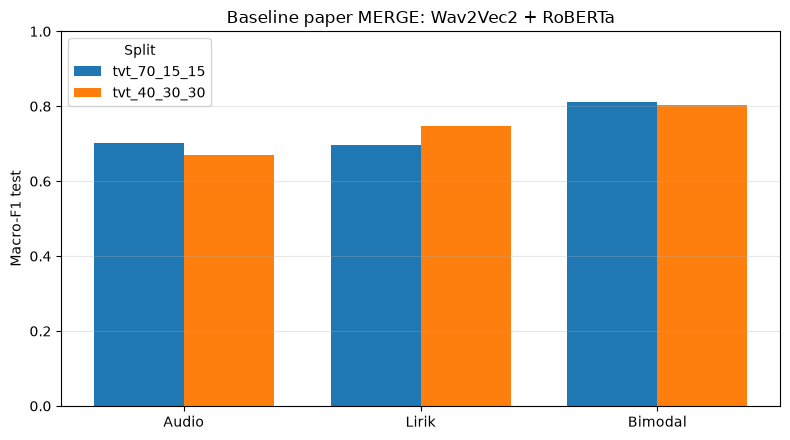


Detail per kelas:

--- Audio | tvt_70_15_15 ---
              precision    recall  f1-score   support

          Q1     0.7722    0.7625    0.7673        80
          Q2     0.9381    0.9286    0.9333        98
          Q3     0.5802    0.6104    0.5949        77
          Q4     0.5200    0.5065    0.5132        77

    accuracy                         0.7169       332
   macro avg     0.7026    0.7020    0.7022       332
weighted avg     0.7182    0.7169    0.7174       332


--- Audio | tvt_40_30_30 ---
              precision    recall  f1-score   support

          Q1     0.7062    0.7862    0.7440       159
          Q2     0.8878    0.8744    0.8810       199
          Q3     0.5758    0.4967    0.5333       153
          Q4     0.5157    0.5359    0.5256       153

    accuracy                         0.6883       664
   macro avg     0.6714    0.6733    0.6710       664
weighted avg     0.6867    0.6883    0.6862       664


--- Lirik | tvt_70_15_15 ---
              precisi

In [10]:
# ============================================================
# 8. Ringkasan dan visualisasi
# ============================================================
summary = pd.DataFrame(RUN_ROWS)
metric_cols = ["accuracy", "precision_macro", "recall_macro", "macro_f1", "weighted_f1"]
summary = summary.sort_values(["dataset", "split"]).reset_index(drop=True)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)

show_cols = ["dataset", "split", *metric_cols, "optimizer", "lr", "batch_size",
             "best_epoch", "epochs_run"]
print("Hasil test:")
display(summary[show_cols].round(4))

pivot = summary.pivot(index="dataset", columns="split", values="macro_f1")
pivot = pivot.reindex([d for d in DATASET_ORDER if d in pivot.index])
print("\nMacro-F1 per model dan split:")
display(pivot.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(pivot.index))
width = 0.38
for i, split in enumerate(SPLITS):
    if split in pivot.columns:
        ax.bar(x + (i - 0.5) * width, pivot[split].values, width, label=split)
ax.set_xticks(x)
ax.set_xticklabels(pivot.index)
ax.set_ylabel("Macro-F1 test")
ax.set_ylim(0, 1)
ax.set_title("Baseline paper MERGE: Wav2Vec2 + RoBERTa")
ax.legend(title="Split")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "macro_f1_comparison.png", dpi=160)
plt.show()

print("\nDetail per kelas:")
for name in DATASET_ORDER:
    for split in SPLITS:
        p = RESULTS_DIR / name.lower() / split / "classification_report.txt"
        if p.exists():
            print(f"\n--- {name} | {split} ---")
            print(p.read_text())


## 9. Catatan interpretasi

- **F1 macro** adalah metrik utama karena distribusi quadrant tidak seimbang.
- Perbedaan hasil antara 70-15-15 dan 40-30-30 dapat mencerminkan stabilitas model serta ukuran data latih.
- Audio-only dan lirik-only memakai dataset lengkap masing-masing, sedangkan bimodal memakai MERGE Bimodal Complete; ini mengikuti profil dataset paper.
- Feature extraction memakai model pretrained **frozen**; Conv1D dan dense layers dilatih dari fitur tersebut.
- Hyperparameter search dijalankan terpisah untuk setiap model/split dengan TPE Bayesian dan early stopping pada validation accuracy.
- Confusion matrix, classification report, prediksi test, trial history, dan checkpoint tersimpan di `results/paper_dl/` dan `checkpoints/paper_dl/`.
